# Double QLearner

In [4]:
class DoubleQlearner:
    def __init__(self, state_shape, num_action, epsilon=0.1, learning_rate=0.001, discount_factor=0.9):
        self.state_shape = state_shape # bordar vijegi state khas - vijegi haye yek state
        self.num_action = num_action
        self.learning_rate = learning_rate
        self.discount_factor = discount_factor
        self.epsilon = epsilon

        self.weight1 = np.zeros((self.num_action , self.state_shape)) # sotun = yek vijegi az state feli - satr = action haye momken
        self.weight2 = np.zeros((self.num_action , self.state_shape))

    def select_action(self, state):
        q_values1 = np.dot(self.weight1 , state) # estefade az zarb dakheli weight haye yek amal  dar bordar vijegi state feli
        q_values2 = np.dot(self.weight2 , state)
        q_values = q_values1 + q_values2
        if np.random.rand() < self.epsilon: #esploration
            action=np.random.randint(0, self.num_action)
        else:#exploitation
            action = np.argmax(q_values)
        return action

    def update(self, state, next_state, reward, action):
        cur_q_values1 = np.dot(self.weight1 , state)
        next_q_values1 = np.dot(self.weight1 , next_state)
        best_next_q_value1 = max(next_q_values1)

        cur_q_values2 = np.dot(self.weight2 , state)
        next_q_values2 = np.dot(self.weight2 , next_state)
        best_next_q_value2 = max(next_q_values2)


        target1 = reward + self.discount_factor * best_next_q_value2
        target2 = reward + self.discount_factor * best_next_q_value1

        self.weight1[action , :] += self.learning_rate * (target1 - cur_q_values1[action]) * state
        self.weight2[action , :] += self.learning_rate * (target2 - cur_q_values2[action]) * state



In [5]:
import gymnasium as gym
import numpy as np

n_episodes = 1000
total_reward =[]
env = gym.make('CartPole-v1')
agent = DoubleQlearner(env.observation_space._shape[0] , env.action_space.n)

for i in range(n_episodes):
    state , info = env.reset()
    episode_rewards=[]
    while True: # gam haye yek episode
        action=agent.select_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        episode_rewards.append(reward)
        agent.update(state, next_state, reward, action)
        state=next_state
        if terminated:
            break
    total_reward.append(np.sum(episode_rewards))

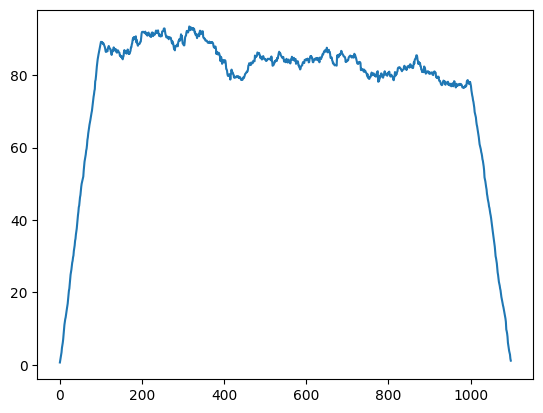

In [6]:
import matplotlib.pyplot as plt
plt.plot(np.convolve(total_reward, np.ones(100)/100))